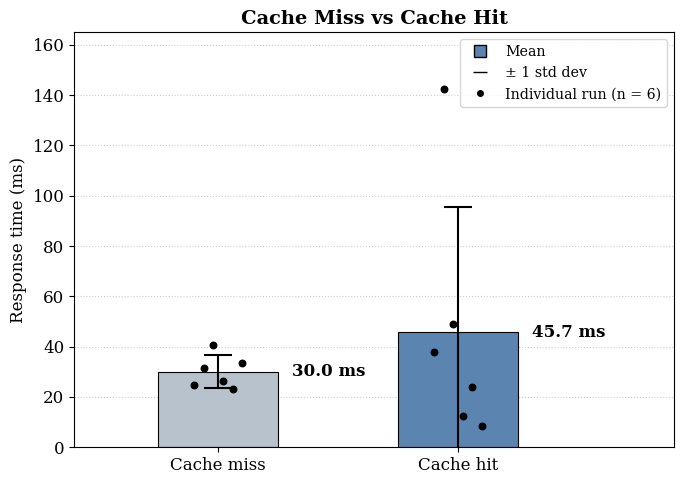

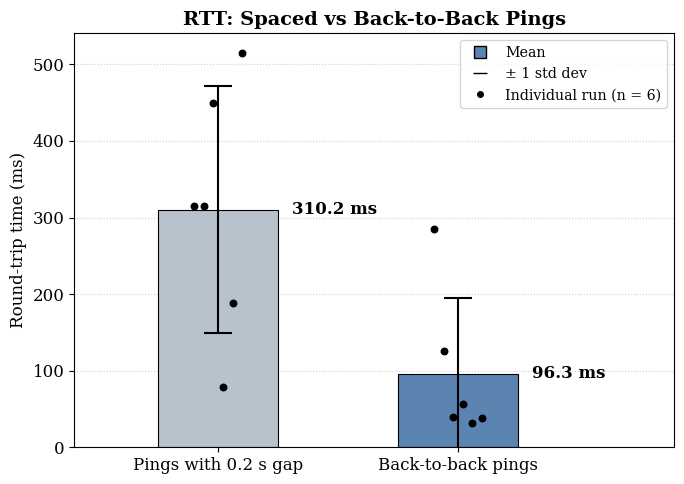

In [1]:
import statistics
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# Raw data values for our metrics (n = 6 runs each)
rtt = [315.13, 315.09, 450.00, 78.21, 188.24, 514.66]
burst = [285.42, 126.27, 39.60, 56.23, 31.60, 38.85]
miss = [24.85, 31.65, 40.61, 26.22, 23.25, 33.35]
hit = [37.97, 142.54, 48.96, 12.48, 23.97, 8.35]

# Global plot styling setup using serif font
plt.rcParams["font.family"] = "serif"
plt.rcParams["font.serif"] = ["Times New Roman", "Liberation Serif", "DejaVu Serif"]
plt.rcParams["font.size"] = 12

def compare(a, b, labels, ylabel, title, filename, colors, custom_yticks=None, ylim_max=None, legend_fontsize=10.2):
    # Set up figure dimensions
    fig, ax = plt.subplots(figsize=(7, 5))
    data = [a, b]
    
    # Calculate means and standard deviations
    means = [statistics.mean(v) for v in data]
    spreads = [statistics.stdev(v) for v in data]
    
    # Plotting the main bars with error bars
    ax.bar([0, 1], means, yerr=spreads, capsize=10, color=colors, edgecolor="black", linewidth=0.8, width=0.5, error_kw={"elinewidth": 1.5, "capthick": 1.5}, zorder=2)
    
    # Scatter individual data points with jitter
    offsets = [-0.10, -0.06, -0.02, 0.02, 0.06, 0.10]
    for x, v in zip([0, 1], data):
        ax.scatter([x + o for o in offsets], v, color="black", s=22, zorder=4)
        
    # Display mean value text next to each bar
    for x, m in zip([0, 1], means):
        ax.text(x + 0.31, m, "%.1f ms" % m, va="center", ha="left", fontweight="bold")
        
    # Axis formatting
    ax.set_xticks([0, 1])
    ax.set_xticklabels(labels)
    ax.set_xlim(-0.6, 1.9)
    
    if custom_yticks is not None:
        plt.yticks(custom_yticks)
    if ylim_max is not None:
        ax.set_ylim(0, ylim_max)
    else:
        ax.set_ylim(bottom=0)
        
    ax.set_ylabel(ylabel)
    ax.set_title(title, fontsize=14, fontweight="bold")
    ax.grid(axis="y", linestyle=":", alpha=0.6, zorder=0)
    ax.set_axisbelow(True)
    
    # Custom legend configuration
    handles = [
        Line2D([0], [0], color=colors[1], marker="s", linestyle="", markeredgecolor="black", markersize=8, label="Mean"),
        Line2D([0], [0], color="black", marker="_", linestyle="", markersize=10, label="\u00b1 1 std dev"),
        Line2D([0], [0], color="black", marker="o", linestyle="", markersize=4, label="Individual run (n = 6)"),
    ]
    ax.legend(handles=handles, loc="upper right", frameon=True, fontsize=legend_fontsize)
    
    # Save figure output
    fig.tight_layout()
    fig.savefig(filename, dpi=300)

# Generate first comparison chart
compare(miss, hit, ["Cache miss", "Cache hit"], "Response time (ms)", "Cache Miss vs Cache Hit", "graph1_miss_vs_hit.png", ["#b8c2cc", "#5b84b1"], custom_yticks=[0, 20, 40, 60, 80, 100, 120, 140, 160], ylim_max=165, legend_fontsize=10.2)

# Generate second comparison chart
compare(rtt, burst, ["Pings with 0.2 s gap", "Back-to-back pings"], "Round-trip time (ms)", "RTT: Spaced vs Back-to-Back Pings", "graph2_rtt.png", ["#b8c2cc", "#5b84b1"], legend_fontsize=10.2)

plt.show()